# Regression trees to find CV thresholds 

In [33]:
# Import libraries
import pandas as pd
from pathlib import Path
from sklearn import tree
import matplotlib.pyplot as plt
import numpy as np
import dtreeviz

In [34]:
# Choose sample and target variable
n_pixels = 5000
target_var = "rue" # or rue?

In [35]:
# Load data
dir_tables = Path("/Users/Wanja/Documents/non-equilibrium_data/tables_wgs84_allyears/")
train_path = dir_tables / f"table_wgs84_2002-2023_train_{n_pixels}px_seed42.parquet"
test_path = dir_tables / f"table_wgs84_2002-2023_test1_{n_pixels}px_seed42.parquet"
df_train = pd.read_parquet(train_path)
df_test = pd.read_parquet(test_path)
print(df_train.shape)
print(df_train.columns)

(110000, 42)
Index(['tmmn_mean', 'tmmx_mean', 'tmmn_min', 'tmmn_max', 'tmmx_min',
       'tmmx_max', 'pr_sum', 'veg_tmmn_mean', 'veg_tmmx_mean', 'veg_tmmn_min',
       'veg_tmmn_max', 'veg_tmmx_min', 'veg_tmmx_max', 'veg_pr_sum',
       'vegetation_length', 'Gpp', 'Npp', 'Npp_QC', 'elevation_mean',
       'longitude', 'latitude', 'year', 'iso3', 'name', 'continent', 'region',
       'rue', 'pr_sum_cv', 'veg_pr_sum_cv', 'Npp_cv', 'location_id', 'year_sc',
       'tmmn_mean_sc', 'tmmx_mean_sc', 'pr_sum_sc', 'veg_tmmn_mean_sc',
       'veg_tmmx_mean_sc', 'veg_pr_sum_sc', 'vegetation_length_sc',
       'elevation_mean_sc', 'pr_sum_cv_sc', 'veg_pr_sum_cv_sc'],
      dtype='str')


In [36]:
def get_leaf_segments(regr):
    """Return (x_lo, x_hi, value, n_samples) for every leaf, sorted along x."""
    t = regr.tree_
    segments = []

    def walk(node, lo, hi):
        left, right = t.children_left[node], t.children_right[node]
        if left == right:  # both are -1 for a leaf
            segments.append((lo, hi, t.value[node][0][0], t.n_node_samples[node]))
            return
        thr = t.threshold[node]
        walk(left, lo, thr)    # samples with x <= thr
        walk(right, thr, hi)   # samples with x >  thr

    walk(0, -np.inf, np.inf)
    return sorted(segments, key=lambda s: s[0])

In [37]:
def run_tree(df_train, df_test, target_var, cv_var, max_depth=1):

    # Prepare training and testing data
    X_train = df_train[[cv_var]]
    y_train = df_train[[target_var]]
    X_test = df_test[[cv_var]]
    y_test = df_test[[target_var]]

    # Fit regression tree
    regr = tree.DecisionTreeRegressor(max_depth=max_depth)
    regr.fit(X_train, y_train)
    y_pred = regr.predict(X_test)

    # Leaf values taken from tree_.value, clipped to the data range for plotting
    x_min, x_max = X_train[cv_var].min(), X_train[cv_var].max()
    segments = get_leaf_segments(regr)

    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    axs[0].scatter(X_train, y_train, s=20, alpha=0.2, label="Training data")

    # Decision boundaries (finite segment edges, excluding the data min/max)
    for i, (lo, hi, val, n) in enumerate(segments[1:]):
        axs[0].axvline(lo, color="red", linestyle="--", lw=1.5,
                       label="Decision boundary" if i == 0 else None)

    # Leaf values as horizontal lines, labelled with value and n
    for i, (lo, hi, val, n) in enumerate(segments):
        lo_c, hi_c = max(lo, x_min), min(hi, x_max)
        axs[0].hlines(val, lo_c, hi_c, color="red", lw=1.5,
                      label="Leaf value" if i == 0 else None)
    
    axs[0].set_xlabel(cv_var)
    axs[0].set_ylabel(target_var)
    axs[0].set_title(f"Regression tree {cv_var}")
    axs[0].legend()

    tree.plot_tree(regr, proportion=True, ax=axs[1], feature_names=[cv_var])
    plt.show()

    return regr, X_train, y_train, X_test, y_test, y_pred

In [38]:
cv_var = "pr_sum_cv"
X_train = np.array(df_train[[cv_var]])
y_train = np.array(df_train[[target_var]])

regr = tree.DecisionTreeRegressor(max_depth=1)
regr.fit(X_train, y_train)
viz = dtreeviz.model(regr, X_train, y_train, target_name=target_var)
viz.view(scale = 3)

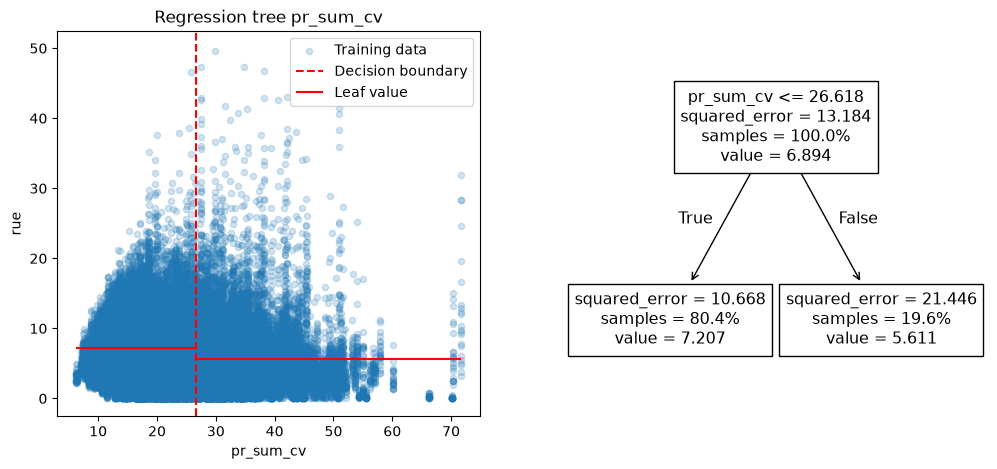

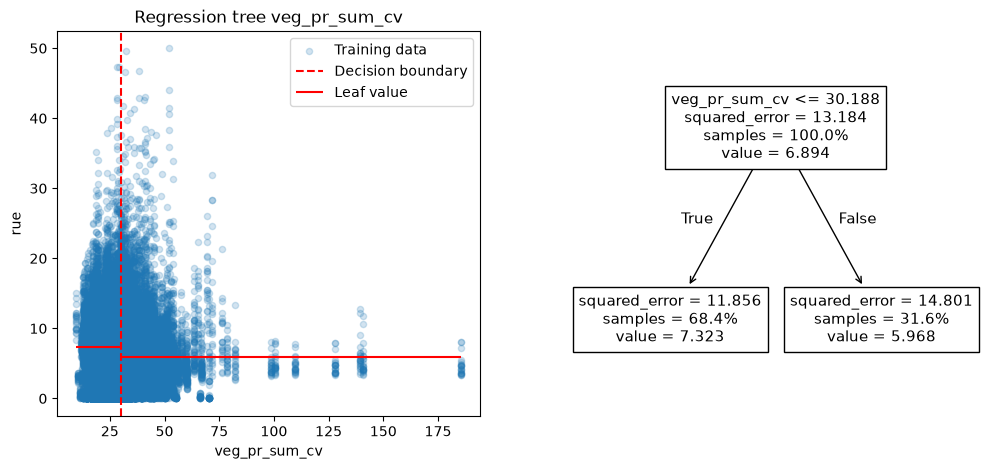

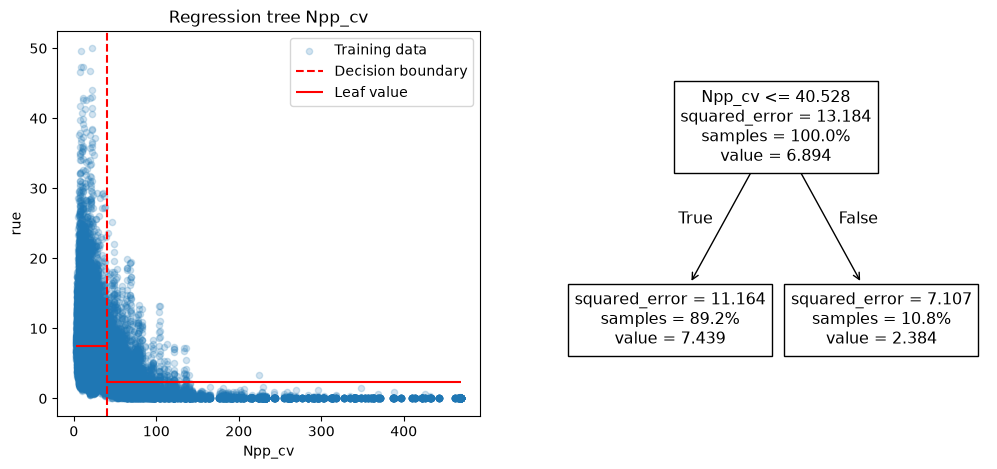

In [39]:
# Run regression trees for each CV variable
for cv_var in ["pr_sum_cv", "veg_pr_sum_cv", "Npp_cv"]:
    regr, X_train, y_train, X_test, y_test, y_pred = run_tree(df_train, df_test, target_var, cv_var)